# Logistic Regression — v1

**Lê Văn Hiếu — 3124411091 · Nhóm 10 · UCI 697**

Đánh giá LR cố định trên các fold chung, phân tích lỗi từng lớp và khoảng cách Train–Validation; đối chiếu với Dummy v1 ở notebook riêng.

Notebook này chỉ trình bày/chạy **Logistic Regression v1**. Code và cấu hình ở `models/m05_logistic_regression/v1/`; notebook từng phiên bản ở `notebooks/m05_logistic_regression/v1.ipynb`, sau này thêm v2–v10 khi có thí nghiệm tương ứng.

Mặc định **Run All đọc run đã huấn luyện**, không fit lại. Mục 5 cho phép chạy mới bằng code dùng chung, tạo `run_id` mới và không ghi đè kết quả. Chạy lại cùng cấu hình vẫn là v1, không tự tăng version.

Chọn kernel `.venv`. Từ gốc repo: `python -m pip install -r final/requirements-notebook.txt`.

## 1. Môi trường và đường dẫn

Tự tìm final/ từ vị trí notebook; không dùng đường dẫn riêng của tác giả.

In [1]:
from pathlib import Path
import sys
import os
import json
import hashlib
import importlib.util
import platform
import pandas as pd
import numpy as np
import yaml
from IPython.display import display, Image

candidates = [p for base in [Path.cwd(), *Path.cwd().parents] for p in [base, base / 'final']]
FINAL = next(p.resolve() for p in candidates if (p / 'src/data.py').is_file() and (p / 'data/raw/data.csv').is_file())
sys.path.insert(0, str(FINAL))
os.environ.setdefault('MPLCONFIGDIR', str(FINAL.parent / '.venv/matplotlib-cache'))
from src.data import load_student_data, load_splits, LABELS
from src.features import make_preprocessor
from src.evaluate import run_cv_experiment

print('Python:', platform.python_version())
print('Project:', FINAL.name)

Python: 3.12.14
Project: final


## 2. Dữ liệu và nhãn

Loader kiểm chứng checksum/schema, giữ nguyên thứ tự dòng và tách Target riêng ở y; không sửa CSV nguồn.

In [2]:
X, y = load_student_data()
assert X.shape == (4424, 36) and 'Target' not in X.columns
source = json.loads((FINAL / 'data/source_manifest.json').read_text(encoding='utf-8'))
print('X:', X.shape, '| y:', y.shape)
print('SHA-256:', source['csv_sha256'])
display(y.value_counts().reindex(LABELS).rename_axis('Nhãn').to_frame('Số mẫu'))

X: (4424, 36) | y: (4424,)
SHA-256: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae


,Số mẫu
Nhãn,
Dropout,1421
Enrolled,794
Graduate,2209


## 3. Bộ chia chung và tiền xử lý

80/20 stratify, seed 42; CV 5-fold trên Train. Nạp file chỉ số có sẵn, không chia riêng. Vị trí trong folds tương đối với X_train.

LR dùng 18 cột StandardScaler, 10 cột One-Hot và 8 cột nhị phân giữ nguyên. Tạo Pipeline mới trong mỗi fold; chỉ fit encoder/scaler trên phần Train của fold. Không imputation, loại ngoại lệ, resampling hoặc thêm đặc trưng ở v1.

In [3]:
train_ids, test_ids, folds, split_manifest = load_splits()
X_train, y_train = X.iloc[train_ids], y.iloc[train_ids]
assert not set(train_ids) & set(test_ids)
print('Train:', len(train_ids), '| Test:', len(test_ids), '| CV:', len(folds))
fold_summary = []
for number, (fit, valid) in enumerate(folds, 1):
    row = {'Fold': number, 'Fit': len(fit), 'Validation': len(valid)}
    row.update({label: int((y_train.iloc[valid] == label).sum()) for label in LABELS})
    fold_summary.append(row)
display(pd.DataFrame(fold_summary).set_index('Fold'))

preprocessor = make_preprocessor()
assert not hasattr(preprocessor, 'transformers_')
print('Preprocessor LR mới tạo chưa fit.')

Train: 3539 | Test: 885 | CV: 5


,Fit,Validation,Dropout,Enrolled,Graduate
Fold,,,,,
1,2831,708,227,127,354
2,2831,708,227,127,354
3,2831,708,228,127,353
4,2831,708,228,127,353
5,2832,707,227,127,353


Preprocessor LR mới tạo chưa fit.


## 4. Cấu hình và model factory

L2, C=1, lbfgs, max_iter=2000, tol=1e-4, class_weight=None. Không tuning. Factory được nạp từ train.py của LR, không viết lại thuật toán trong notebook.

In [4]:
MODEL_ID = 'm05_logistic_regression'
model_dir = FINAL / 'models' / MODEL_ID / 'v1'
spec = importlib.util.spec_from_file_location(f'train_{MODEL_ID}_v1', model_dir / 'train.py')
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
config = yaml.safe_load((model_dir / 'config.yaml').read_text(encoding='utf-8'))
assert config['model_id'] == MODEL_ID and config['version'] == 'v1'
print('Tham số:', config['params'])
print(module.make_model(config))

Tham số: {'C': 1.0, 'l1_ratio': 0.0, 'solver': 'lbfgs', 'max_iter': 2000, 'tol': 0.0001, 'class_weight': None, 'fit_intercept': True, 'random_state': 42}
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['Previous qualification '
                                                   '(grade)',
                                                   'Admission grade',
                                                   'Age at enrollment',
                                                   'Unemployment rate',
                                                   'Inflation rate', 'GDP',
                                                   'Curricular units 1st sem '
                                                   '(credited)',
                                                   'Curricular units 1st sem '
                                                   '(enrolled)',
                 

## 5. Đọc run đã có hoặc huấn luyện mới

`RUN_NEW_EXPERIMENT = False`: chỉ đọc kết quả Logistic Regression v1 đã huấn luyện. Đổi thành True để fit 5 fold và fit lại toàn Train; tạo run mới cho riêng model này. Không tạo run của mô hình khác. Không dự đoán hoặc đánh giá Test.

Không chạy nhiều notebook cùng ghi experiments/results.csv đồng thời trong một checkout.

In [5]:
RUN_NEW_EXPERIMENT = False
if RUN_NEW_EXPERIMENT:
    run_path = run_cv_experiment(model_dir / 'config.yaml', module.make_model)
else:
    run_path = FINAL / 'experiments/runs/m05_logistic_regression_v1_20261104T070444_33387318'
    print('Đọc run đã huấn luyện; không fit lại trong lần Run All này.')
assert run_path.is_dir(), 'Chưa có thư mục run'
print('Run:', run_path.name)

Đọc run đã huấn luyện; không fit lại trong lần Run All này.
Run: m05_logistic_regression_v1_20261104T070444_33387318


## 6. Kết quả CV và độ ổn định

Trung bình 5 fold, std ddof=0. Theo dõi Macro-F1, Accuracy, Recall Dropout và gap Train–Validation; không gọi các số này là Test.

,Macro-F1 CV,Std (ddof=0),Accuracy CV,Recall Dropout CV,Train Macro-F1,Gap Train–Validation
Model,,,,,,
m05_logistic_regression,0.6997,0.0099,0.7754,0.7748,0.7557,0.0559


,fold,train_f1_macro,valid_f1_macro,valid_accuracy,valid_recall_Dropout,gap_f1_macro
0,1,0.7460,0.7190,0.7825,0.7533,0.0270
1,2,0.7517,0.6946,0.7782,0.7709,0.0570
2,3,0.7517,0.6919,0.7740,0.7851,0.0597
3,4,0.7632,0.6995,0.7754,0.8114,0.0637
4,5,0.7658,0.6937,0.7666,0.7533,0.0721


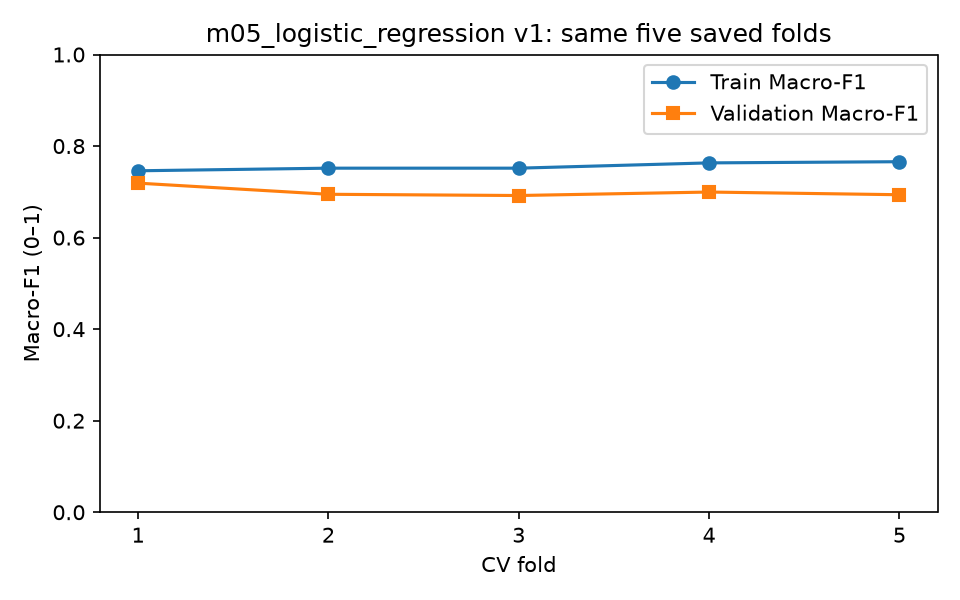

In [6]:
recorded_config = yaml.safe_load((run_path / 'config.yaml').read_text(encoding='utf-8'))
assert recorded_config == config, 'Config khác run; cần chọn đúng version hoặc chạy mới.'
tracking = json.loads((run_path / 'tracking.json').read_text(encoding='utf-8'))
assert tracking['status'] == 'complete'
metrics = json.loads((run_path / 'metrics.json').read_text(encoding='utf-8'))
assert metrics['model_id'] == MODEL_ID and not metrics['test_scored_this_run']
cv = metrics['cv']
display(pd.DataFrame([{
    'Model': MODEL_ID, 'Macro-F1 CV': cv['valid_f1_macro_mean'],
    'Std (ddof=0)': cv['valid_f1_macro_std'], 'Accuracy CV': cv['valid_accuracy_mean'],
    'Recall Dropout CV': cv['valid_recall_Dropout_mean'],
    'Train Macro-F1': cv['train_f1_macro_mean'], 'Gap Train–Validation': cv['gap_f1_macro_mean'],
}]).set_index('Model').round(4))
display(pd.read_csv(run_path / 'fold_metrics.csv')[
    ['fold', 'train_f1_macro', 'valid_f1_macro', 'valid_accuracy', 'valid_recall_Dropout', 'gap_f1_macro']].round(4))
display(Image(filename=str(run_path / 'figures/cv_macro_f1.png')))

LR v1 đạt Macro-F1 CV khoảng 0,6997 ± 0,0099, Accuracy 77,54%, Recall Dropout 77,48%. Mốc Dummy v1 trong notebook m01_baseline/v1.ipynb đạt Macro-F1 CV khoảng 0,2220 trên cùng fold; LR cải thiện khoảng 0,4777. Gap LR khoảng 0,0559; năm fold chỉ mô tả bộ chia hiện có, chưa chứng minh tổng quát sang trường/năm học khác hoặc LR tốt nhất nhóm.

## 7. OOF, lỗi từng lớp và confusion matrix

Mỗi sinh viên Train có một dự đoán từ model không học mẫu đó trong fold. OOF gộp khác CV mean; ma trận có hàng là nhãn thật và cột là dự đoán.

,precision,recall,f1-score,support
label,,,,
Dropout,0.7980,0.7748,0.7863,1137.0
Enrolled,0.5742,0.3780,0.4558,635.0
Graduate,0.8047,0.9185,0.8578,1767.0


Macro-F1 OOF: 0.7


,Dropout,Enrolled,Graduate
true_label,,,
Dropout,881,102,154
Enrolled,155,240,240
Graduate,68,76,1623


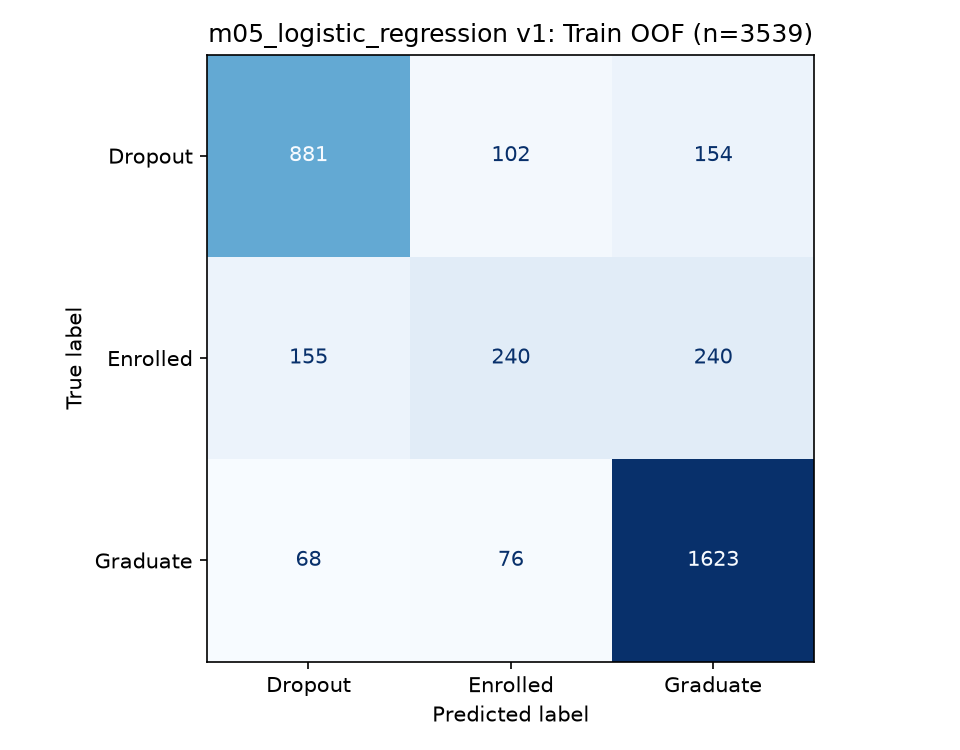

Dropout bị bỏ sót: 256
Cảnh báo Dropout nhầm: 223


In [7]:
classes = pd.read_csv(run_path / 'class_metrics_oof.csv')
display(classes.set_index('label').round(4))
print('Macro-F1 OOF:', round(metrics['oof']['f1_macro'], 4))
cm = pd.read_csv(run_path / 'confusion_matrix.csv', index_col=0)
display(cm)
display(Image(filename=str(run_path / 'figures/confusion_matrix.png')))
print('Dropout bị bỏ sót:', int(cm.loc['Dropout'].sum() - cm.loc['Dropout', 'Dropout']))
print('Cảnh báo Dropout nhầm:', int(cm['Dropout'].sum() - cm.loc['Dropout', 'Dropout']))

LR nhận đúng 881/1.137 Dropout, bỏ sót 256 và có 223 cảnh báo Dropout nhầm. Enrolled khó nhất: Recall khoảng 0,3780, F1 khoảng 0,4558; dễ nhầm sang hai nhãn còn lại. Cần theo dõi đánh đổi giữa bỏ sót và cảnh báo nhầm. Chưa cô lập nguyên nhân gây lỗi và không chứng minh quan hệ nhân quả.

## 8. Truy vết, giới hạn và phiên bản tiếp theo

Run này đã được đối chiếu với kết quả giữa kỳ: metrics khớp trong sai số 1e-12 và OOF trùng hoàn toàn. Git/source hashes ghi code thực dùng; verification.json ghi kiểm chứng độc lập. Run mới chỉ có kiểm tra runtime cho đến khi được đối chiếu riêng.

W&B/Sheets chưa đồng bộ vì checkout chưa có cấu hình. Model joblib chỉ lưu cục bộ; chạy mới để tạo lại. Không nạp model từ nguồn không tin cậy.

Run này không đánh giá Test. Test từng được RF cũ sử dụng; đổi cấu trúc không xóa lịch sử đó. Dữ liệu có HK2 nên không gọi đây là dự đoán ngay khi nhập học.

V2 có thể thử C hoặc class_weight, mỗi lần thay một yếu tố với giả thuyết rõ ràng; giữ dữ liệu/fold để đối chiếu và không lựa chọn bằng Test. Không bắt buộc bản sau tốt hơn. Ablation phối hợp với Phát. Khi thực hiện mới thêm v2.ipynb, v3.ipynb… trong thư mục notebook LR, tối đa theo ngân sách nhóm đã chốt.

In [8]:
info = json.loads((run_path / 'git_info.json').read_text(encoding='utf-8'))
changed = [name for name, digest in info['source_sha256'].items()
           if hashlib.sha256((FINAL / name).read_bytes()).hexdigest() != digest]
print('Source hiện tại khớp lúc chạy:', not changed)
if changed:
    print('File đã thay đổi:', changed)
verify_path = run_path / 'verification.json'
if verify_path.exists():
    print('Kiểm chứng độc lập:', len(json.loads(verify_path.read_text(encoding='utf-8'))['checks_passed']), 'mục đạt')
else:
    print('Run mới chưa có biên bản kiểm chứng độc lập.')
print('Bằng chứng:', run_path.relative_to(FINAL).as_posix())
print('W&B:', tracking['wandb_status'])

Source hiện tại khớp lúc chạy: True
Kiểm chứng độc lập: 13 mục đạt
Bằng chứng: experiments/runs/m05_logistic_regression_v1_20261104T070444_33387318
W&B: not_configured
